# Maskable PPO for Taxi-v4 — Final Project Notebook

This notebook combines the team's environment setup, action masking, PPO explanation, trained model, saved results, and numerical policy-update example into one executable story.

**Project goal.** Train a Maskable PPO agent for Gymnasium Taxi-v4 so that invalid actions are excluded from the policy distribution.

**What this notebook shows:**
1. the Taxi-v4 state and action spaces;
2. state-dependent action masks;
3. how masking changes the action distribution;
4. the exact training configuration and saved model;
5. reproducible evaluation and saved visual results;
6. one small Maskable PPO policy update calculated by hand and verified with PyTorch.

The repository already contains the model trained for **125,000 timesteps**. To keep a normal top-to-bottom run fast and to preserve the submitted artifacts, the notebook loads that model by default instead of retraining it.

## 1. Imports, paths, and reproducibility

Run this notebook either from the repository root or from the `notebooks/` directory. All imports are kept in one cell, and every project path is built from `PROJECT_ROOT`. Fixed seeds are used for Python, NumPy, PyTorch, and Taxi-v4.

In [1]:
from importlib.metadata import version
from pathlib import Path
import random

import gymnasium as gym
import numpy as np
import torch
from IPython.display import Image, display
from sb3_contrib import MaskablePPO
from sb3_contrib.common.maskable.callbacks import MaskableEvalCallback
from sb3_contrib.common.maskable.utils import get_action_masks, is_masking_supported
from sb3_contrib.common.wrappers import ActionMasker
from stable_baselines3.common.monitor import Monitor

SEED = 42
TOTAL_TIMESTEPS = 125_000
RUN_TRAINING = False

current_dir = Path.cwd().resolve()
root_candidates = [current_dir, current_dir.parent]
PROJECT_ROOT = next(
    (path for path in root_candidates if (path / 'requirements.txt').exists() and (path / 'notebooks').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run the notebook from the repository root or the notebooks directory.')

MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR = PROJECT_ROOT / 'results'
MODEL_PATH = MODELS_DIR / 'maskable_ppo_taxi.zip'
CURVE_PATH = RESULTS_DIR / 'training_curve.png'
DEMO_PATH = RESULTS_DIR / 'taxi_demo.gif'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

for required_path in (MODEL_PATH, CURVE_PATH, DEMO_PATH):
    if not required_path.exists():
        raise FileNotFoundError(f'Missing project artifact: {required_path}')

print('Project root found:', PROJECT_ROOT.name)
print('Python packages:', {name: version(name) for name in ['gymnasium', 'stable-baselines3', 'sb3-contrib', 'torch']})
print('Retraining enabled:', RUN_TRAINING)

Project root found: MaskablePPO-Project
Python packages: {'gymnasium': '1.4.0', 'stable-baselines3': '2.9.0', 'sb3-contrib': '2.9.0', 'torch': '2.14.1'}
Retraining enabled: False


## 2. Environment and action masks

Taxi-v4 has **500 discrete states** and **6 discrete actions**. A state encodes the taxi row, taxi column, passenger location, and destination. The reward is −1 per ordinary step, +20 for a successful delivery, and −10 for an illegal pickup or drop-off.

The action mask contains one value for every action: `1` means valid and `0` means invalid. For the seeded initial state used throughout the team notebooks, only South, North, and West are valid.

In [2]:
ACTION_NAMES = ['South', 'North', 'East', 'West', 'Pickup', 'Dropoff']

def mask_fn(env):
    """Return the Taxi-v4 mask for the current underlying state."""
    return env.unwrapped.action_mask(env.unwrapped.s)


def make_masked_env(seed=None, monitor_path=None, render_mode=None):
    env = gym.make('Taxi-v4', render_mode=render_mode)
    env = Monitor(env, filename=monitor_path)
    env = ActionMasker(env, mask_fn)
    env.reset(seed=seed)
    return env


environment = make_masked_env(seed=SEED)
state, info = environment.reset(seed=SEED)
initial_mask = get_action_masks(environment)
decoded_state = tuple(environment.unwrapped.decode(state))

print('Environment:', environment.unwrapped.spec.id)
print('Observation space:', environment.observation_space)
print('Action space:', environment.action_space)
print('Initial state:', state, 'decoded as', decoded_state)
print('Masking supported:', is_masking_supported(environment))
print('Action mask:', initial_mask)
for action_id, action_name in enumerate(ACTION_NAMES):
    print(f'{action_id}: {action_name:<8} -> {"valid" if initial_mask[action_id] else "invalid"}')

assert state == 386
assert np.array_equal(initial_mask, np.array([1, 1, 0, 1, 0, 0]))
assert initial_mask.shape == (environment.action_space.n,)
assert initial_mask.any()
environment.close()

Environment: Taxi-v4
Observation space: Discrete(500)
Action space: Discrete(6)
Initial state: 386 decoded as (3, 4, 1, 2)
Masking supported: True
Action mask: [1 1 0 1 0 0]
0: South    -> valid
1: North    -> valid
2: East     -> invalid
3: West     -> valid
4: Pickup   -> invalid
5: Dropoff  -> invalid


### State-dependent masks

The mask changes with the state. In particular, Pickup is valid only when the taxi is at the passenger location, and Dropoff is valid when the taxi carries the passenger at the destination.

In [3]:
inspection_env = gym.make('Taxi-v4')
test_cases = [
    ('Away from passenger', (2, 2, 0, 1)),
    ('At passenger location', (0, 0, 0, 1)),
    ('Passenger inside taxi', (2, 2, 4, 1)),
    ('At destination', (0, 4, 4, 1)),
]

case_masks = {}
for label, state_components in test_cases:
    encoded_state = inspection_env.unwrapped.encode(*state_components)
    case_mask = inspection_env.unwrapped.action_mask(encoded_state)
    case_masks[label] = case_mask
    valid_actions = [name for name, valid in zip(ACTION_NAMES, case_mask) if valid]
    print(f'{label:<22} state={encoded_state:<3} mask={case_mask.tolist()} valid={valid_actions}')

for case_mask in case_masks.values():
    assert case_mask.shape == (6,) and np.isin(case_mask, [0, 1]).all() and case_mask.any()
assert case_masks['Away from passenger'][4] == 0
assert case_masks['At passenger location'][4] == 1
assert case_masks['Passenger inside taxi'][4] == 0
assert case_masks['At destination'][5] == 1
inspection_env.close()
print('All action-mask checks passed.')

Away from passenger    state=241 mask=[1, 1, 1, 1, 0, 0] valid=['South', 'North', 'East', 'West']
At passenger location  state=1   mask=[1, 0, 1, 0, 1, 0] valid=['South', 'East', 'Pickup']
Passenger inside taxi  state=257 mask=[1, 1, 1, 1, 0, 0] valid=['South', 'North', 'East', 'West']
At destination         state=97  mask=[1, 0, 0, 1, 0, 1] valid=['South', 'West', 'Dropoff']
All action-mask checks passed.


## 3. Standard PPO and Maskable PPO

PPO is an on-policy actor-critic algorithm. The actor produces action logits, and the critic estimates the state value. Maskable PPO uses the same advantage estimation and clipped PPO objective, but it applies the current state mask to the action distribution before sampling and again when log-probabilities are calculated during optimization.

Invalid logits are replaced by a very large negative value before softmax. Therefore, invalid actions receive zero probability and the remaining probability mass is redistributed across valid actions.

In [4]:
example_logits = np.array([1.2, 0.8, 1.5, 0.2, 1.0, -0.5])
example_mask = np.array([1, 1, 0, 1, 0, 0], dtype=bool)

def numpy_softmax(values):
    shifted = values - np.max(values)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum()

standard_probabilities = numpy_softmax(example_logits)
masked_logits = np.where(example_mask, example_logits, -np.inf)
masked_probabilities_numpy = numpy_softmax(masked_logits)

print(f'{"Action":<8} {"Standard PPO":>14} {"Maskable PPO":>14}')
for name, standard_probability, masked_probability in zip(
    ACTION_NAMES, standard_probabilities, masked_probabilities_numpy
):
    print(f'{name:<8} {standard_probability:>14.3f} {masked_probability:>14.3f}')

assert np.all(masked_probabilities_numpy[~example_mask] == 0.0)
assert np.isclose(masked_probabilities_numpy.sum(), 1.0)

Action     Standard PPO   Maskable PPO
South             0.228          0.491
North             0.153          0.329
East              0.308          0.000
West              0.084          0.180
Pickup            0.187          0.000
Dropoff           0.042          0.000


## 4. Training method and saved model

The team trained an `MlpPolicy` Maskable PPO model on CPU with the following configuration.

| Parameter | Value |
|---|---:|
| learning rate | 0.0003 |
| rollout length (`n_steps`) | 1024 |
| batch size | 64 |
| discount factor (`gamma`) | 0.99 |
| GAE lambda | 0.95 |
| optimization epochs | 10 |
| seed | 42 |
| total timesteps | 125,000 |

During the original run, a mask-aware evaluation callback checked the policy every 5,000 steps on 20 episodes and saved the best checkpoint. The final file in `models/maskable_ppo_taxi.zip` is that saved trained model. Its archive records the original core environment: Python 3.14.4, Gymnasium 1.4.0, Stable-Baselines3 2.9.0, PyTorch 2.14.1, and NumPy 2.5.4. The core versions in `requirements.txt` match this record.

The code below is executable in both modes. With `RUN_TRAINING = False` (the default), it loads the submitted model. Setting it to `True` performs a new 125,000-step run in a separate `reproduced_run/` directory, so the submitted results are not overwritten.

In [5]:
if RUN_TRAINING:
    reproduced_dir = PROJECT_ROOT / 'reproduced_run'
    reproduced_models = reproduced_dir / 'models'
    reproduced_results = reproduced_dir / 'results'
    reproduced_models.mkdir(parents=True, exist_ok=True)
    reproduced_results.mkdir(parents=True, exist_ok=True)

    train_env = make_masked_env(
        seed=SEED,
        monitor_path=str(reproduced_results / 'training_monitor'),
    )
    callback_env = make_masked_env(seed=SEED + 1)
    model = MaskablePPO(
        policy='MlpPolicy',
        env=train_env,
        learning_rate=3e-4,
        n_steps=1024,
        batch_size=64,
        gamma=0.99,
        gae_lambda=0.95,
        n_epochs=10,
        seed=SEED,
        device='cpu',
        verbose=0,
    )
    evaluation_callback = MaskableEvalCallback(
        callback_env,
        best_model_save_path=str(reproduced_models / 'best'),
        log_path=str(reproduced_results / 'evaluation'),
        eval_freq=5_000,
        n_eval_episodes=20,
        deterministic=True,
        verbose=0,
    )
    model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=evaluation_callback)
    model = MaskablePPO.load(reproduced_models / 'best' / 'best_model.zip', device='cpu')
    model.save(reproduced_models / 'maskable_ppo_taxi')
    train_env.close()
    callback_env.close()
    model_source = reproduced_models / 'maskable_ppo_taxi.zip'
else:
    model = MaskablePPO.load(MODEL_PATH, device='cpu')
    model_source = MODEL_PATH

print('Loaded model:', model_source.relative_to(PROJECT_ROOT))

Loaded model: models/maskable_ppo_taxi.zip


## 5. Evaluation of the submitted model

We evaluate deterministic actions on 100 episodes with explicit seeds 1042–1141. At every step, the current valid-action mask is supplied to the policy. A successful Taxi-v4 episode terminates after correct delivery, so termination is also used to calculate the success rate.

Notebook 04 reported **7.67 ± 2.51** on the evaluation environment after that environment had also been used by the training callback. Here we use an independent fixed episode set, making the validation reproducible without rerunning training. The episode sample is different, but the submitted model is unchanged.

In [6]:
N_EVAL_EPISODES = 100
evaluation_env = make_masked_env(seed=SEED + 1_000)
successes = 0
episode_returns = []
episode_lengths = []
for episode in range(N_EVAL_EPISODES):
    observation, _ = evaluation_env.reset(seed=SEED + 1_000 + episode)
    terminated = truncated = False
    episode_return = 0.0
    steps = 0
    while not (terminated or truncated):
        action_mask = get_action_masks(evaluation_env)
        action, _ = model.predict(
            observation, action_masks=action_mask, deterministic=True
        )
        assert action_mask[int(action)], 'The model selected an invalid action.'
        observation, reward, terminated, truncated, _ = evaluation_env.step(int(action))
        episode_return += reward
        steps += 1
    successes += int(terminated)
    episode_returns.append(episode_return)
    episode_lengths.append(steps)

mean_reward = float(np.mean(episode_returns))
std_reward = float(np.std(episode_returns))
success_rate = successes / N_EVAL_EPISODES
mean_episode_length = float(np.mean(episode_lengths))
evaluation_env.close()

print(f'Mean reward: {mean_reward:.2f} ± {std_reward:.2f}')
print(f'Success rate: {success_rate:.1%}')
print(f'Mean episode length: {mean_episode_length:.1f} steps')

assert success_rate == 1.0
assert np.isclose(mean_reward, 7.31, atol=0.01)
assert np.isclose(std_reward, 3.04, atol=0.01)
assert np.isclose(mean_episode_length, 13.69, atol=0.01)

Mean reward: 7.31 ± 3.04
Success rate: 100.0%
Mean episode length: 13.7 steps


### Saved training and demonstration results

The learning curve and GIF below are the artifacts produced by the original 125,000-step team run and committed to `main`. The final 100-episode rolling mean training reward was **7.25**. The demonstration completes a delivery in **13 steps** with return **8**.

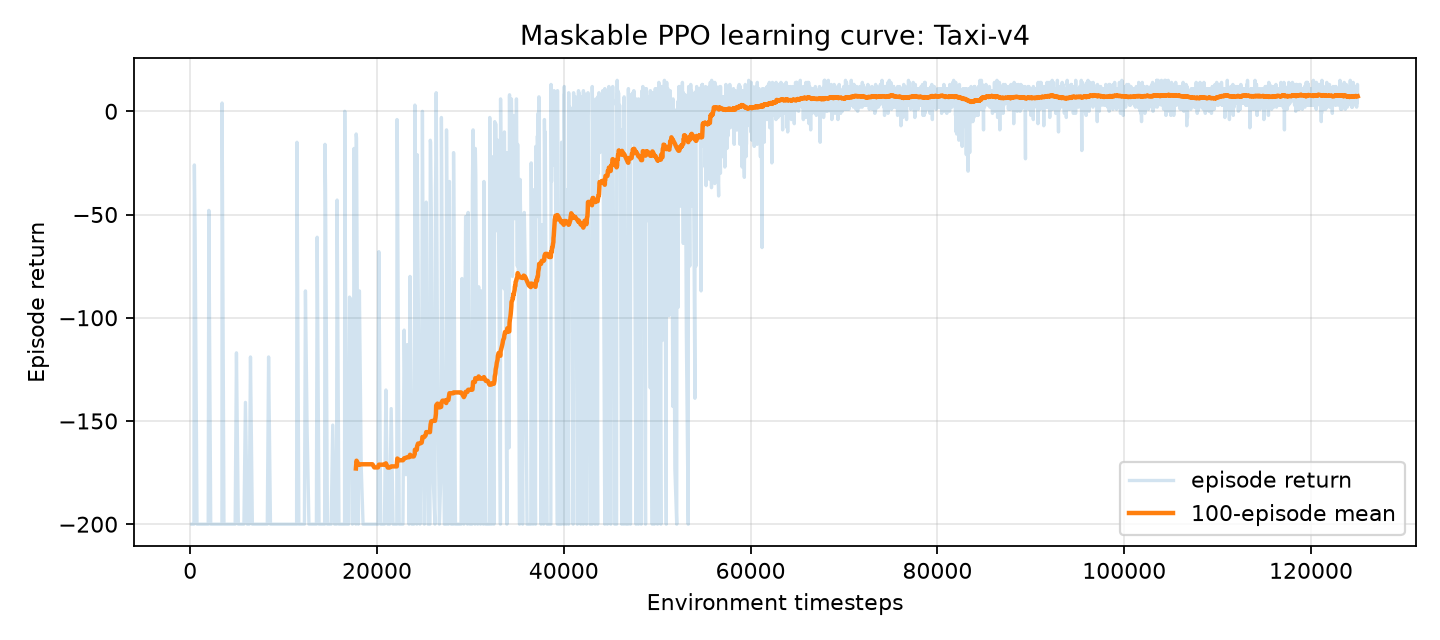

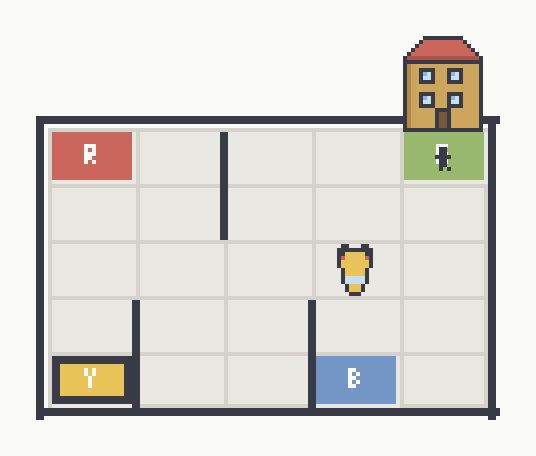

In [7]:
display(Image(filename=str(CURVE_PATH)))
display(Image(filename=str(DEMO_PATH)))

## 6. Small numerical Maskable PPO policy update

This section satisfies the project requirement to show how the algorithm updates a policy with one small example. We reuse the real Taxi-v4 state **386**, its mask **[1, 1, 0, 1, 0, 0]**, and the six project actions.

The selected action is **South**. The initial logits, fixed advantage $A=2.0$, and illustrative SGD learning rate $0.1$ are chosen for easy arithmetic; they are not extracted from the saved model or training rollout. The full model uses Adam, batches, GAE, advantage normalization, and value and entropy terms.

Initial logits are $\log([4, 3.5, 5, 2.5, 3, 2])$. Before masking, the six weights sum to 20. After masking, only South, North, and West remain, and their weights sum to 10. Therefore,

$$\pi_{old}=[0.40,\;0.35,\;0,\;0.25,\;0,\;0].$$

In [8]:
numerical_mask = torch.tensor([1, 1, 0, 1, 0, 0], dtype=torch.bool)
selected_action = 0
fixed_advantage = torch.tensor(2.0, dtype=torch.float64)
epsilon = 0.2
learning_rate = 0.1

initial_logits = torch.log(
    torch.tensor([4.0, 3.5, 5.0, 2.5, 3.0, 2.0], dtype=torch.float64)
)
old_logits = initial_logits.detach().clone()
policy_logits = torch.nn.Parameter(initial_logits.clone())

def masked_torch_probabilities(logits):
    return torch.softmax(logits.masked_fill(~numerical_mask, -torch.inf), dim=0)

with torch.no_grad():
    unmasked_probabilities = torch.softmax(old_logits, dim=0)
    old_probabilities = masked_torch_probabilities(old_logits)
    old_selected_probability = old_probabilities[selected_action].clone()

print(f'{"ID":<3} {"Action":<8} {"Mask":>5} {"Unmasked":>10} {"Masked":>10}')
for action_id, action_name in enumerate(ACTION_NAMES):
    print(
        f'{action_id:<3} {action_name:<8} {int(numerical_mask[action_id]):>5}'
        f' {unmasked_probabilities[action_id].item():>10.6f}'
        f' {old_probabilities[action_id].item():>10.6f}'
    )

ID  Action    Mask   Unmasked     Masked
0   South        1   0.200000   0.400000
1   North        1   0.175000   0.350000
2   East         0   0.250000   0.000000
3   West         1   0.125000   0.250000
4   Pickup       0   0.150000   0.000000
5   Dropoff      0   0.100000   0.000000


### PPO clipped objective before the update

For one sample, PPO uses

$$r=\frac{\pi_\theta(a\mid s)}{\pi_{old}(a\mid s)},\qquad L^{CLIP}=\min(rA,\;\operatorname{clip}(r,1-\epsilon,1+\epsilon)A),\qquad \ell_\pi=-L^{CLIP}.$$

Initially the current and old policies are identical. Thus $r=0.40/0.40=1$, both surrogate terms equal 2, and the policy loss is $-2$.

In [9]:
current_probabilities = masked_torch_probabilities(policy_logits)
current_selected_probability = current_probabilities[selected_action]
probability_ratio = current_selected_probability / old_selected_probability
clipped_ratio = torch.clamp(probability_ratio, 1.0 - epsilon, 1.0 + epsilon)
unclipped_surrogate = probability_ratio * fixed_advantage
clipped_surrogate = clipped_ratio * fixed_advantage
ppo_objective = torch.minimum(unclipped_surrogate, clipped_surrogate)
policy_loss = -ppo_objective

for name, value in [
    ('Old South probability', old_selected_probability),
    ('Current South probability', current_selected_probability),
    ('Probability ratio', probability_ratio),
    ('Unclipped surrogate', unclipped_surrogate),
    ('Clipped surrogate', clipped_surrogate),
    ('Policy loss', policy_loss),
]:
    print(f'{name:<28} {value.item():.6f}')

Old South probability        0.400000
Current South probability    0.400000
Probability ratio            1.000000
Unclipped surrogate          2.000000
Clipped surrogate            2.000000
Policy loss                  -2.000000


### Gradient and one SGD step calculated by hand

At $r=1$, clipping is inactive. For each valid logit,

$$\frac{\partial \ell_\pi}{\partial z_i}=-Ar(\mathbf{1}_{i=a}-p_i).$$

With $A=2$ and probabilities $[0.40,0.35,0.25]$, the six-action gradient is

$$g=[-1.20,\;0.70,\;0,\;0.50,\;0,\;0].$$

An SGD step $z'=z-0.1g$ changes the valid logits by $[+0.12,-0.07,-0.05]$. After softmax,

$$\pi_{after}\approx[0.444271,\;0.321470,\;0,\;0.234260,\;0,\;0].$$

The new South ratio is $0.444271/0.40\approx1.110677$, which is still inside the clipping interval $[0.8,1.2]$.

In [10]:
logits_before = policy_logits.detach().clone()
probabilities_before = current_probabilities.detach().clone()
optimizer = torch.optim.SGD([policy_logits], lr=learning_rate)
optimizer.zero_grad()
policy_loss.backward()
gradients = policy_logits.grad.detach().clone()
optimizer.step()

with torch.no_grad():
    logits_after = policy_logits.detach().clone()
    probabilities_after = masked_torch_probabilities(policy_logits)
    ratio_after = probabilities_after[selected_action] / old_selected_probability
    loss_after = -torch.minimum(
        ratio_after * fixed_advantage,
        torch.clamp(ratio_after, 1.0 - epsilon, 1.0 + epsilon) * fixed_advantage,
    )

print(
    f'{"Action":<8} {"Logit before":>13} {"Gradient":>10}'
    f' {"Logit after":>13} {"p before":>10} {"p after":>10}'
)
for action_id, action_name in enumerate(ACTION_NAMES):
    print(
        f'{action_name:<8} {logits_before[action_id].item():>13.6f}'
        f' {gradients[action_id].item():>10.6f}'
        f' {logits_after[action_id].item():>13.6f}'
        f' {probabilities_before[action_id].item():>10.6f}'
        f' {probabilities_after[action_id].item():>10.6f}'
    )
print(f'\nSouth probability: {probabilities_before[0].item():.6f} -> {probabilities_after[0].item():.6f}')
print(f'Policy loss: {policy_loss.item():.6f} -> {loss_after.item():.6f}')
print(f'Ratio after update: {ratio_after.item():.6f}')

Action    Logit before   Gradient   Logit after   p before    p after
South         1.386294  -1.200000      1.506294   0.400000   0.444271
North         1.252763   0.700000      1.182763   0.350000   0.321470
East          1.609438   0.000000      1.609438   0.000000   0.000000
West          0.916291   0.500000      0.866291   0.250000   0.234260
Pickup        1.098612   0.000000      1.098612   0.000000   0.000000
Dropoff       0.693147   0.000000      0.693147   0.000000   0.000000

South probability: 0.400000 -> 0.444271
Policy loss: -2.000000 -> -2.221354
Ratio after update: 1.110677


### Separate example where clipping is active

To make clipping visible, consider a separate current policy with valid probabilities $[0.50,0.30,0.20]$. The fixed old South probability is still 0.40, so $r=1.25$. PPO uses the clipped ratio 1.20 and the loss is $-2.40$. Because $A>0$ and the ratio is already above $1+\epsilon$, this sample has zero gradient and gives no incentive to increase South further.

In [11]:
clipping_logits = torch.nn.Parameter(
    torch.log(torch.tensor([5.0, 3.0, 5.0, 2.0, 3.0, 2.0], dtype=torch.float64))
)
clipping_probabilities = masked_torch_probabilities(clipping_logits)
clipping_ratio = clipping_probabilities[selected_action] / old_selected_probability
clipping_loss = -torch.minimum(
    clipping_ratio * fixed_advantage,
    torch.clamp(clipping_ratio, 1.0 - epsilon, 1.0 + epsilon) * fixed_advantage,
)
clipping_loss.backward()

print(f'Hypothetical South probability: {clipping_probabilities[0].item():.6f}')
print(f'Probability ratio: {clipping_ratio.item():.6f}')
print(f'Clipped policy loss: {clipping_loss.item():.6f}')
print('Gradient:', clipping_logits.grad.tolist())

Hypothetical South probability: 0.500000
Probability ratio: 1.250000
Clipped policy loss: -2.400000
Gradient: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


### Numerical checks

In [12]:
assert not old_logits.requires_grad and old_logits.grad is None
assert torch.equal(old_logits, initial_logits)
for probabilities in (
    old_probabilities, probabilities_before, probabilities_after, clipping_probabilities.detach()
):
    assert torch.all(probabilities >= 0)
    assert torch.all(probabilities[~numerical_mask] == 0)
    torch.testing.assert_close(
        probabilities[numerical_mask].sum(), torch.tensor(1.0, dtype=torch.float64)
    )
torch.testing.assert_close(
    gradients, torch.tensor([-1.2, 0.7, 0.0, 0.5, 0.0, 0.0], dtype=torch.float64)
)
torch.testing.assert_close(logits_after, logits_before - learning_rate * gradients)
torch.testing.assert_close(
    probabilities_after[selected_action],
    torch.tensor(0.44427073407933526, dtype=torch.float64),
)
torch.testing.assert_close(policy_loss.detach(), torch.tensor(-2.0, dtype=torch.float64))
torch.testing.assert_close(clipping_loss.detach(), torch.tensor(-2.4, dtype=torch.float64))
assert torch.all(clipping_logits.grad == 0)
print('All numerical policy-update checks passed.')

All numerical policy-update checks passed.


## 7. Final results

| Metric | Result |
|---|---:|
| Training budget | 125,000 timesteps |
| Mean reward reported by the original team run | 7.67 ± 2.51 |
| Clean fixed-seed re-evaluation | 7.31 ± 3.04 |
| Success rate | **100.0%** |
| Mean episode length | 13.7 steps |
| Final 100-episode rolling mean training reward | 7.25 |
| Demo episode | reward 8, 13 steps, successful delivery |

The action mask keeps invalid actions at zero probability during action selection. In the small update, one SGD step increases the selected valid action's probability from **0.400000** to **0.444271**, while invalid actions remain at zero. The separate clipping example shows that PPO removes the incentive for a favorable ratio to move beyond the clipping boundary.

## References

- Schulman et al., [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347)
- [SB3 Contrib: Maskable PPO](https://sb3-contrib.readthedocs.io/en/master/modules/ppo_mask.html)
- [Gymnasium: Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/)